# Computes ground relative cold pool speed AND plots
Computes the ground relative cold pool speed along a transect, following the edge of the cold pool by taking the gradient of the theta perturbation. For the oceanic MCS.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from netCDF4 import Dataset, num2date, date2num
from datetime import datetime
from matplotlib.dates import DateFormatter
import pandas as pd 

import metpy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.ticker as mticker 
from __future__ import print_function
import os
import glob

from metpy.units import units
from matplotlib.ticker import ScalarFormatter
from metpy.interpolate import cross_section

import wrf
import metpy.calc as mpcalc
from metpy.calc import relative_humidity_from_mixing_ratio
from wrf import (to_np, interplevel, geo_bounds, getvar, smooth2d, get_cartopy, cartopy_xlim,
                 cartopy_ylim, latlon_coords, destagger, CoordPair, vertcross, ll_to_xy)

In [16]:
# Set directory where wrfout files reside, and list the files for processing.  Set up for a directory with only wrfout files.
os.chdir("/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1/")
print(os.getcwd())
# Get sorted list of files
datafiles = (sorted(glob.glob("wrfout_d03*")))#17_00:00:00")))
numfiles=len(datafiles)
print(numfiles)
print(datafiles[44])
# Set up for saving graphics files
plotsdir = '/glade/u/home/athornton/wrf_visualization/cold_pool_data/xsec_large/'

/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1
85
wrfout_d03_2018-08-26_04:00:00


In [3]:
# Get base state info for lat and lon
wrf_out_data = xr.open_dataset(datafiles[55])  
p = wrf_out_data["P"]
lats, lons = latlon_coords(p)
lats_np = to_np(lats)
lons_np = to_np(lons)

In [4]:
# Oceanic
lat_min = 5.
lat_max = 10.
lon_min = -20.
lon_max = -18.


In [5]:
# isolate lats and lons
lat = lats_np[0,:,0]
lon = lons_np[0,0,:]

# determine min index (leftmost)
idx = np.where(lat <= lat_min)
min_lat_idx = idx[0][-1]
# determine max index (leftmost)
idx = np.where(lat <= lat_max)
max_lat_idx = idx[0][-1]

idx = np.where(lon <= lon_min)
min_lon_idx = idx[0][-1]
idx = np.where(lon <= lon_max)
max_lon_idx = idx[0][-1]

In [6]:
# Create an aerial abmient theta box ahead of the cross section
lat_max2 = lat_max + 0.5  # expand lat cross section box 0.5 degrees south and north
lat_min2 = lat_min - 0.5
lon_max2 = lon_min  + 0.75   # shift longitude one degree to the west, ahead of the cold pool
lon_min2 = lon_min 
# final dimensions of base state box are 1x1 degree lat/lon

idx = np.where(lat <= lat_min2)
min_lat_idx_50 = idx[0][-1]
idx = np.where(lat <= lat_max2)
max_lat_idx_50 = idx[0][-1]

idx = np.where(lon <= lon_min2)
min_lon_idx_50 = idx[0][-1]
idx = np.where(lon <= lon_max2)
max_lon_idx_50 = idx[0][-1]

In [7]:
start_point = CoordPair(lat=lat_min, lon=lon_min)
end_point   = CoordPair(lat=lat_max, lon=lon_max)

In [8]:
def create_fig():
    # Fig quality
    plt.rcParams['savefig.dpi'] = 155
    
    fig = plt.figure(figsize=(24,8))
    ax = plt.axes()
    
    plt.gca().invert_yaxis()
    
    ## THETA
    levels = np.arange(-10, 10, 1)
    cf = ax.contourf(dist, height, theta_p_cross, levels=levels, cmap='RdYlBu_r', extend='both')
    cb = plt.colorbar(cf)
    cb.set_label('$K$', fontsize=16)
    
    ## PLOT FEATURES
    ax.set_xlabel('Gridpoint distance (km)', fontsize=18)
    ax.set_ylabel('Pressure (hPa)', fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=12)
    plt.yscale("log")
    max_yticks = 11
    yloc = plt.MaxNLocator(max_yticks)
    ax.yaxis.set_major_locator(yloc)
    
    ax.set_ylim(1000,100)
    # Change formatter or else tick values will be in exponential form
    ax.yaxis.set_major_formatter(ScalarFormatter())
    
    plt.title('Theta perturbation, vertical motion, u,w winds', loc='left', weight='bold', fontsize=18)
    plt.title('Date: '+str(filetime)+'\n('+str(lat_min)+'N,'+str(lon_min)+'W)'+'\n('+str(lat_max)+'N,'+str(lon_max)+'W)', loc='right', fontsize=16)
    
    plt.savefig(plotsdir+'XNORTH_section_theta_large'+filetime+'.png')
    plt.show()
    #plt.close()


WRF valid time:  2018-08-26_14:30


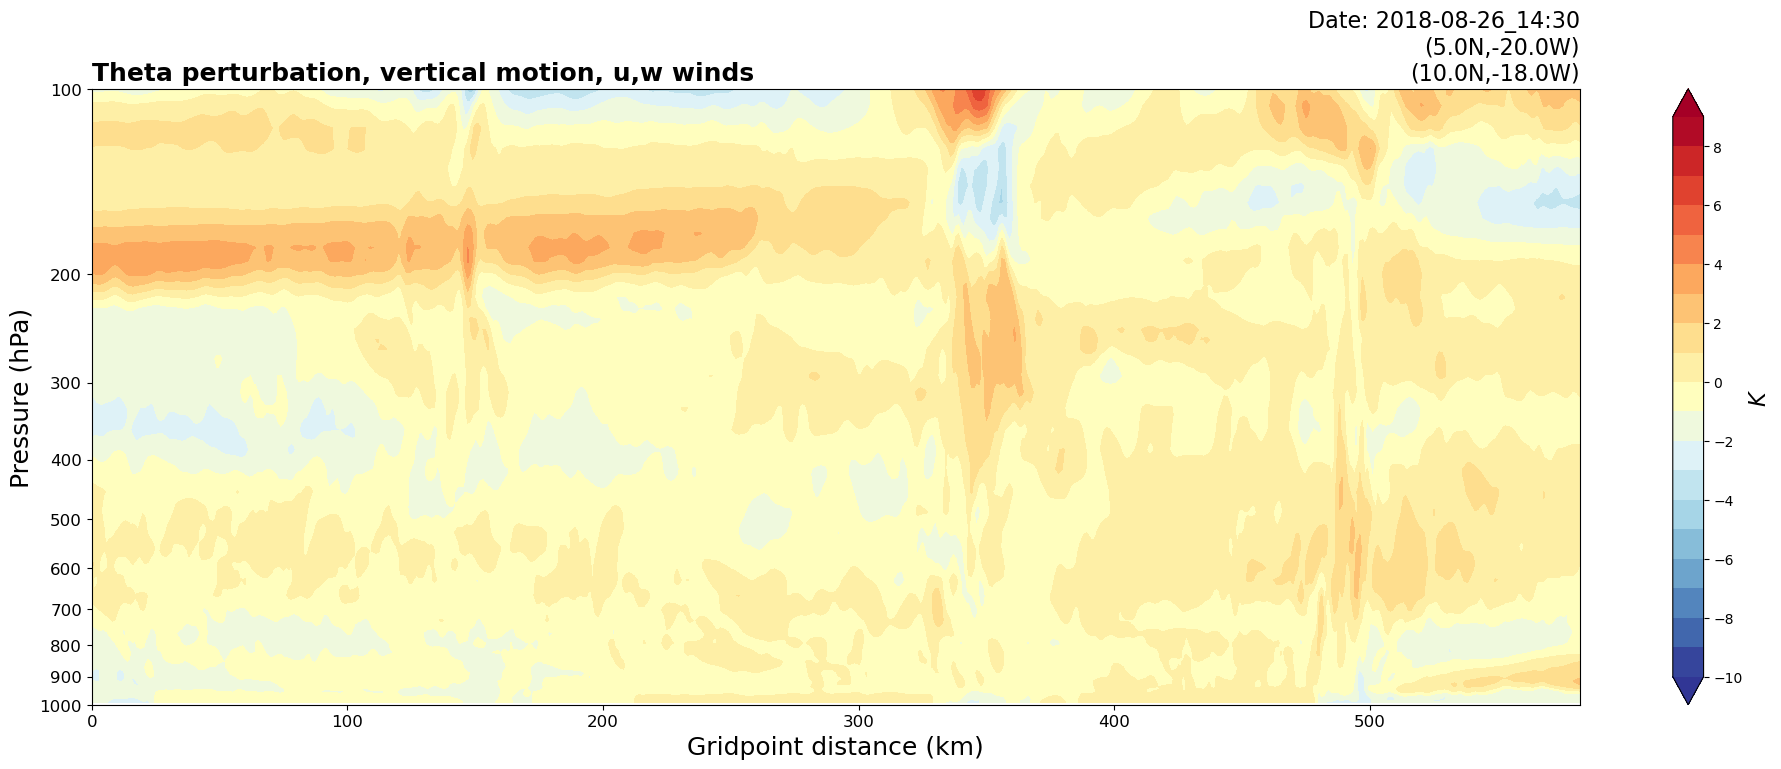

WRF valid time:  2018-08-26_15:00


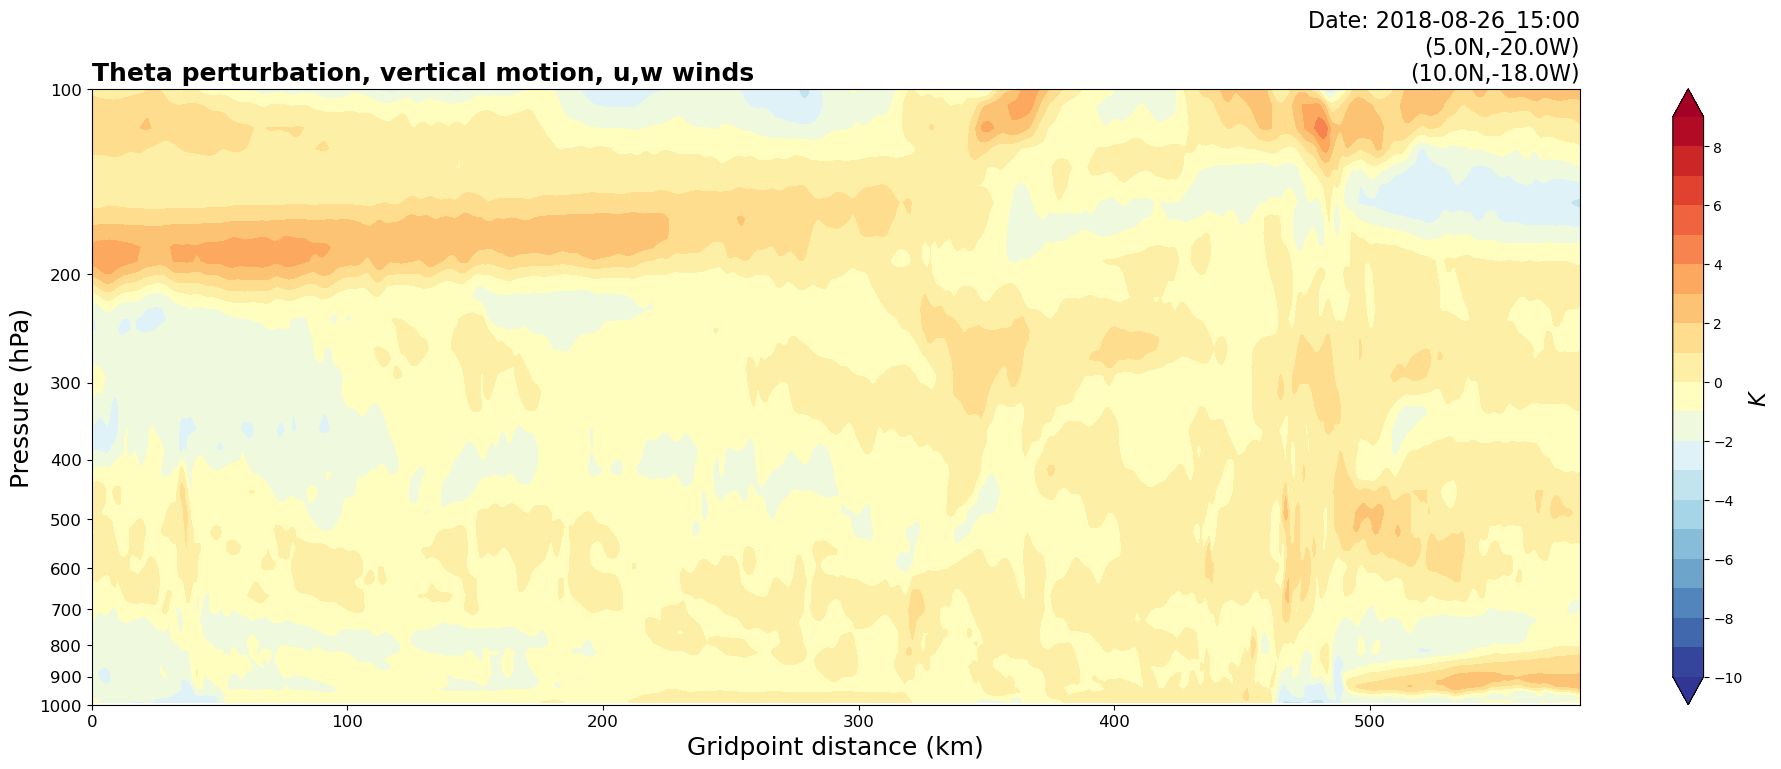

0
495
0.69346714
463
WRF valid time:  2018-08-26_15:30


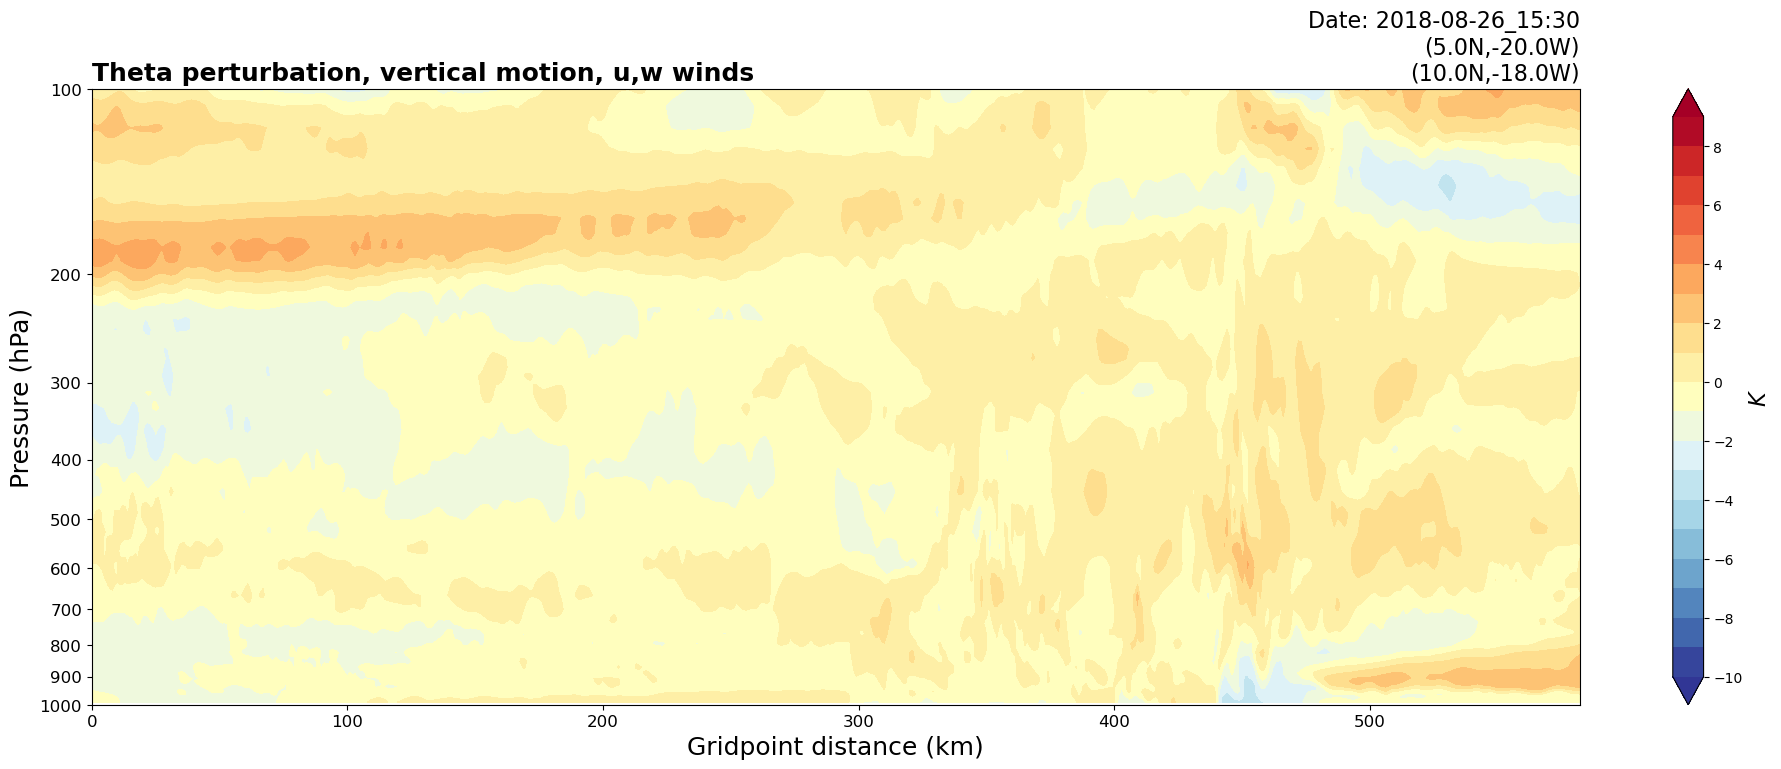

1
463
1.2526529
440
WRF valid time:  2018-08-26_16:00


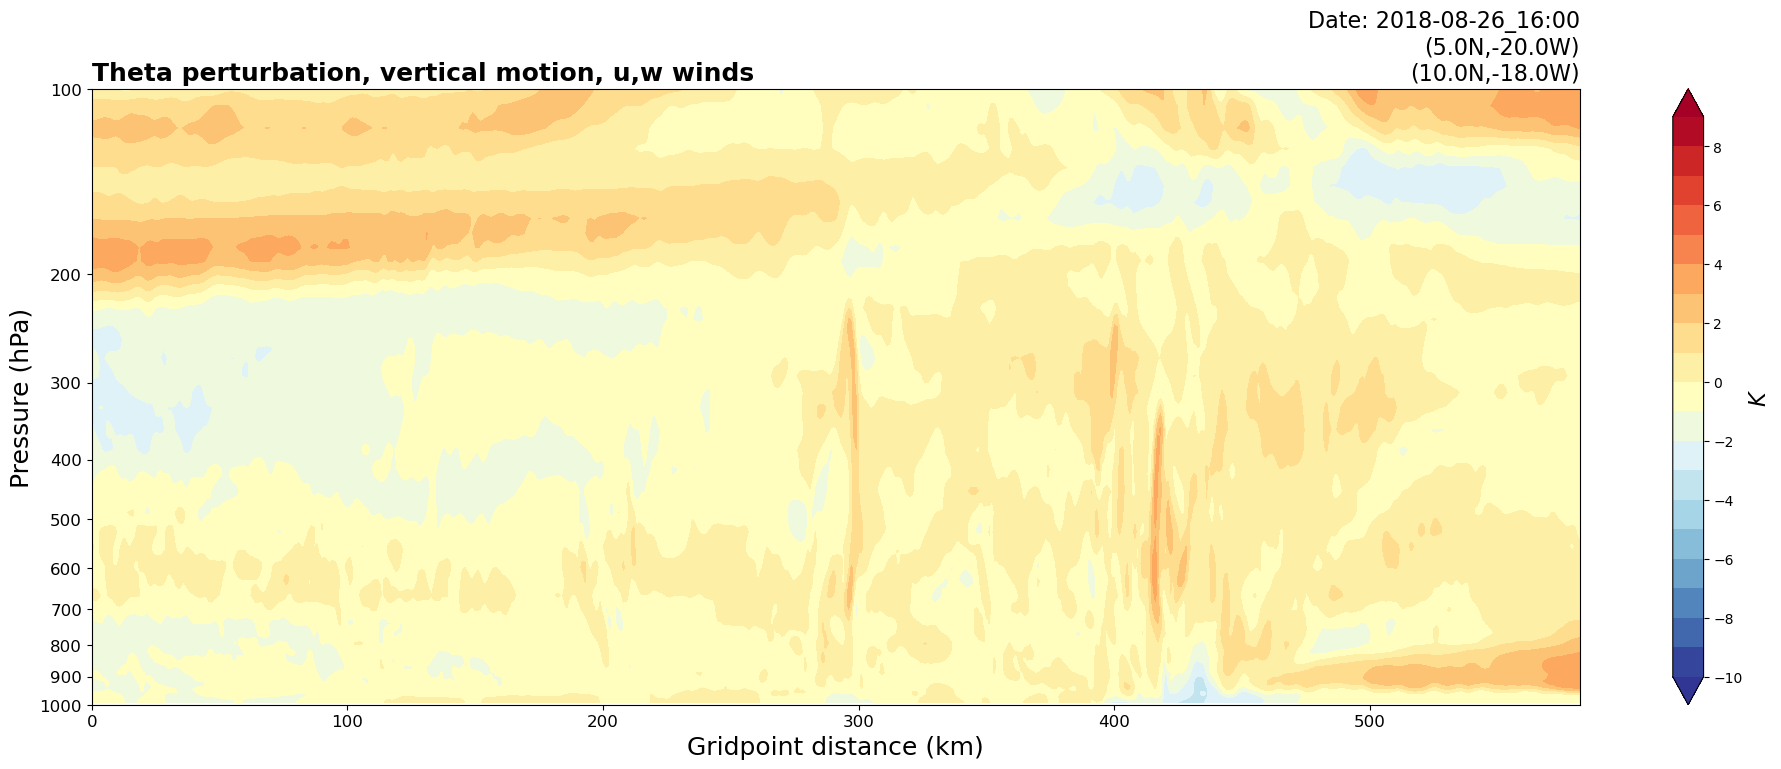

2
440
0.8890683
419
WRF valid time:  2018-08-26_16:30


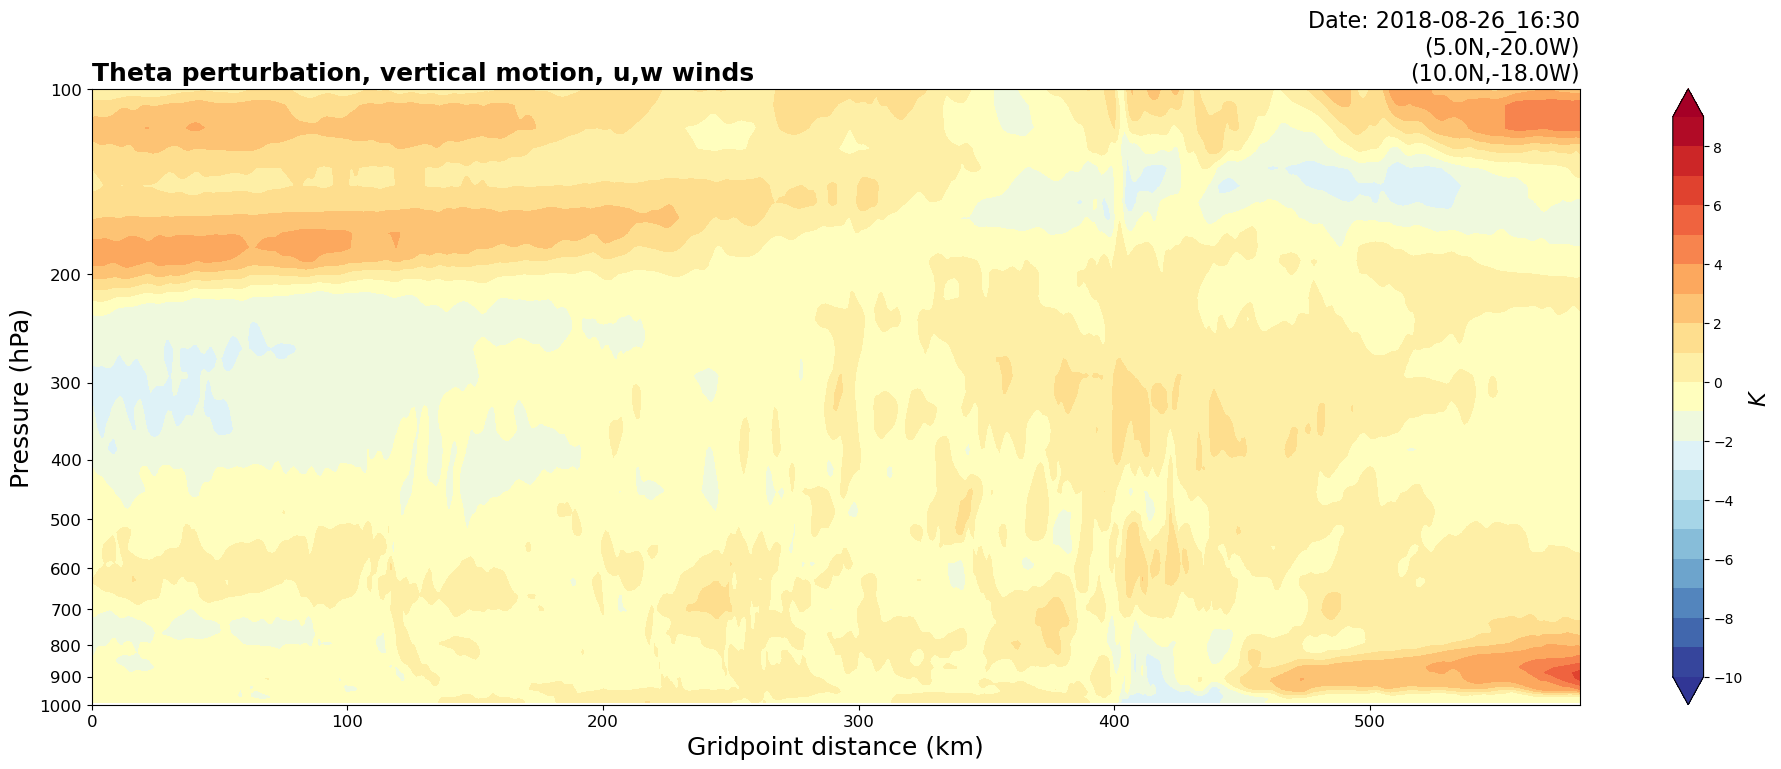

3
419
0.6063076
402
WRF valid time:  2018-08-26_17:00


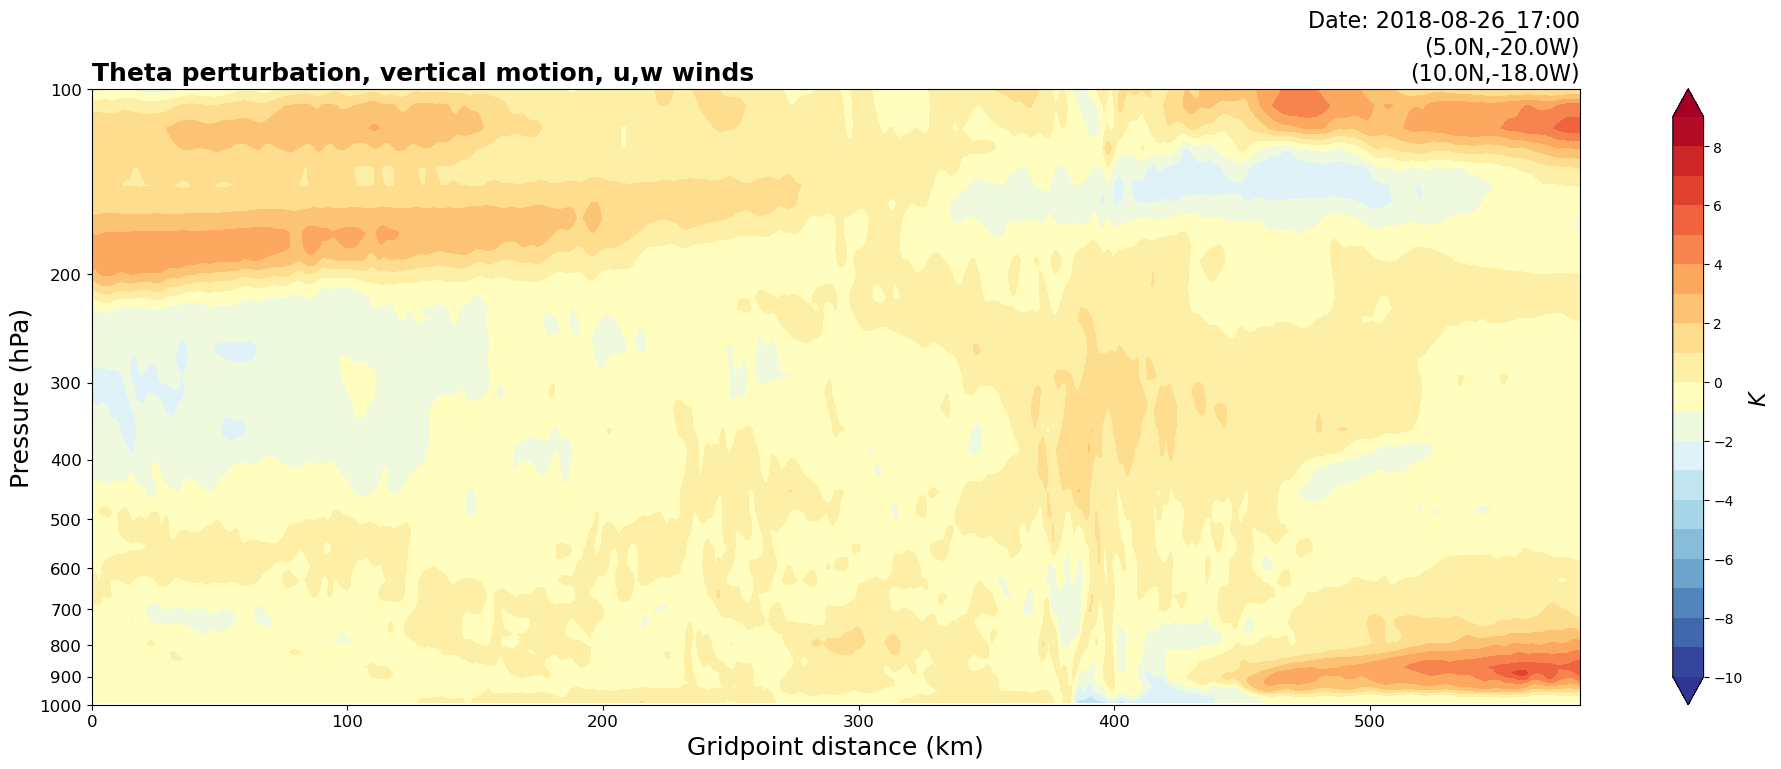

4
402
1.0008715
384
WRF valid time:  2018-08-26_17:30


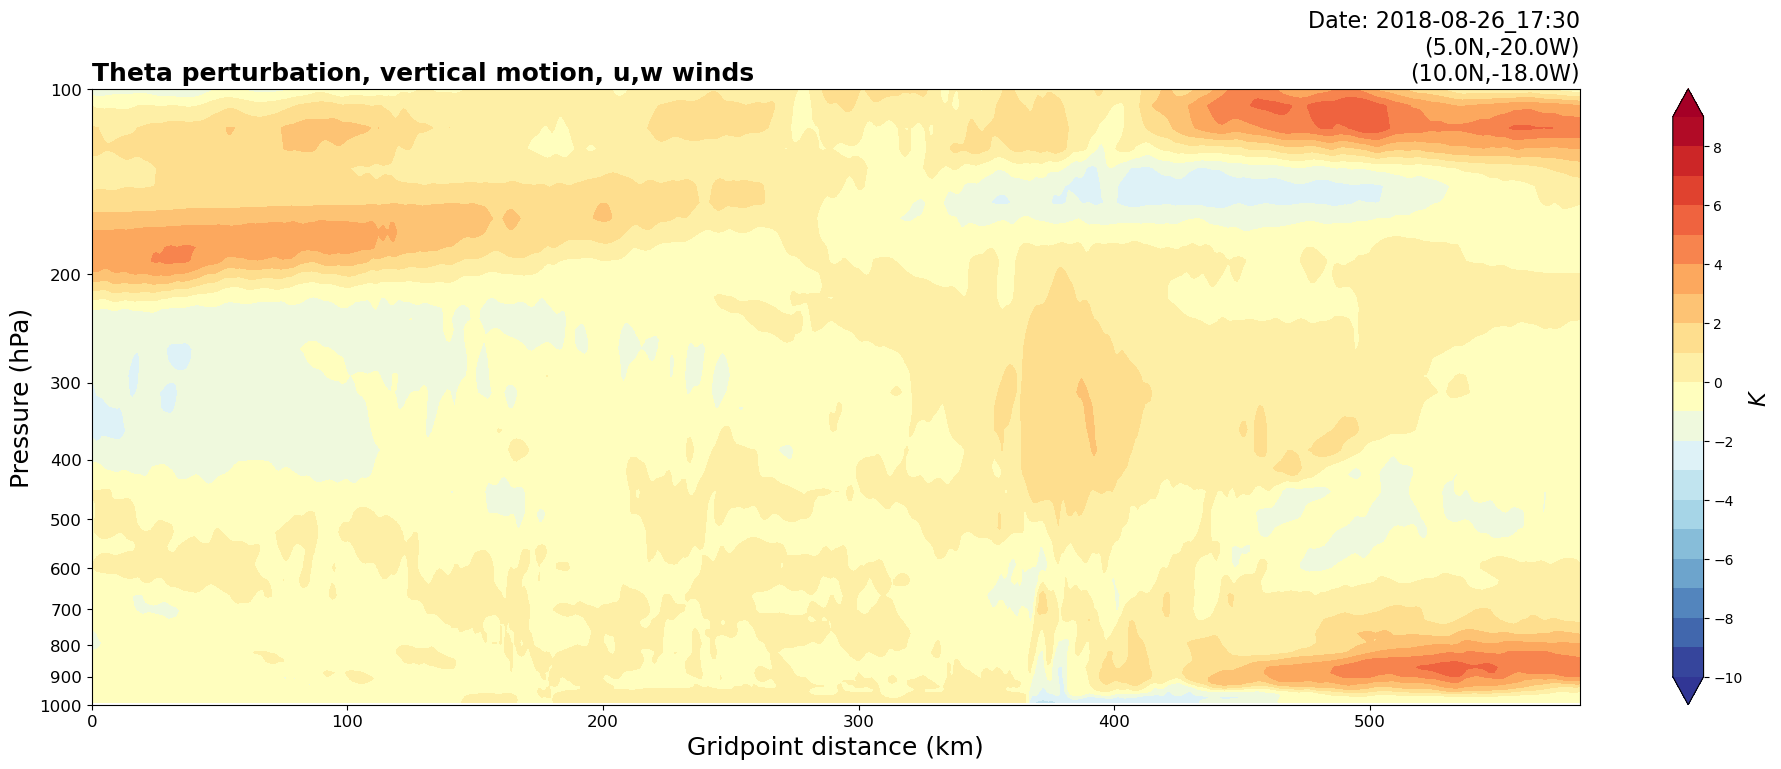

5
384
0.8630689
367
WRF valid time:  2018-08-26_18:00


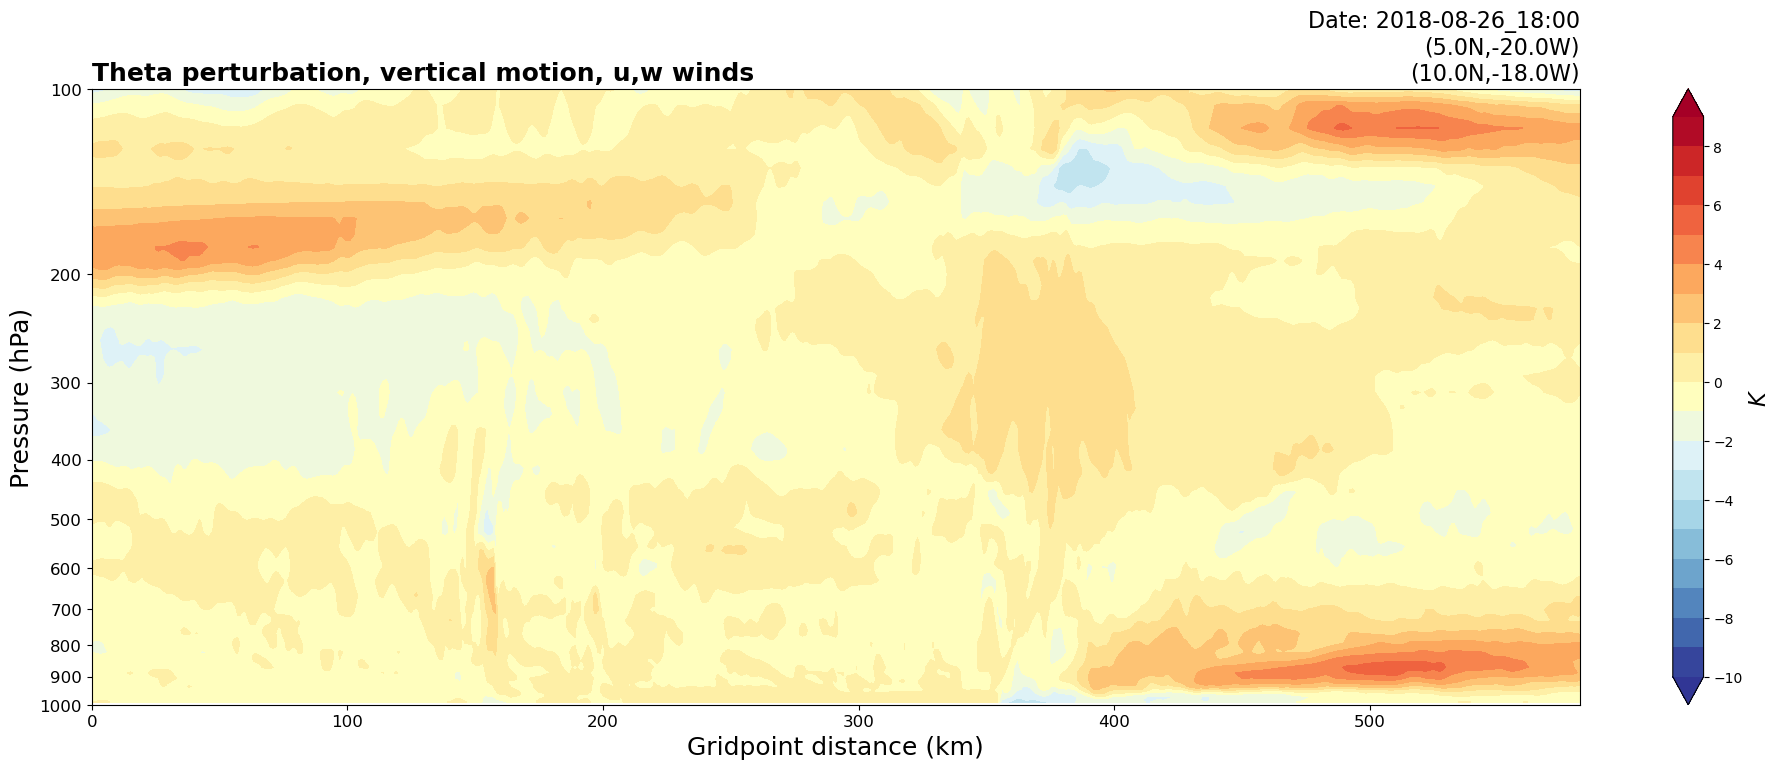

6
367
0.7728845
355
WRF valid time:  2018-08-26_18:30


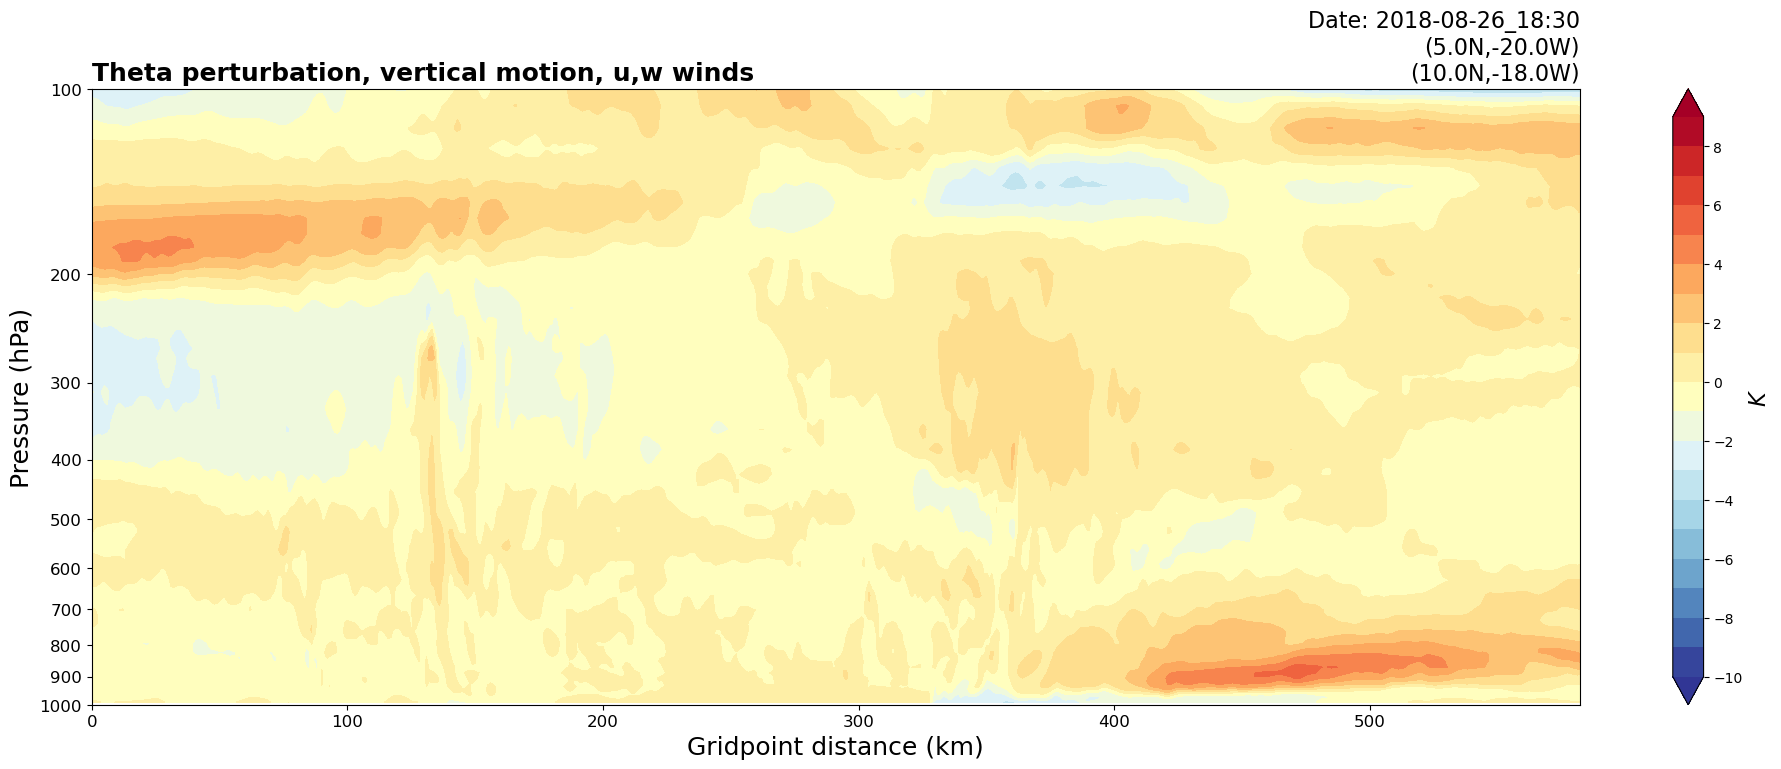

7
355
0.6744444
329
WRF valid time:  2018-08-26_19:00


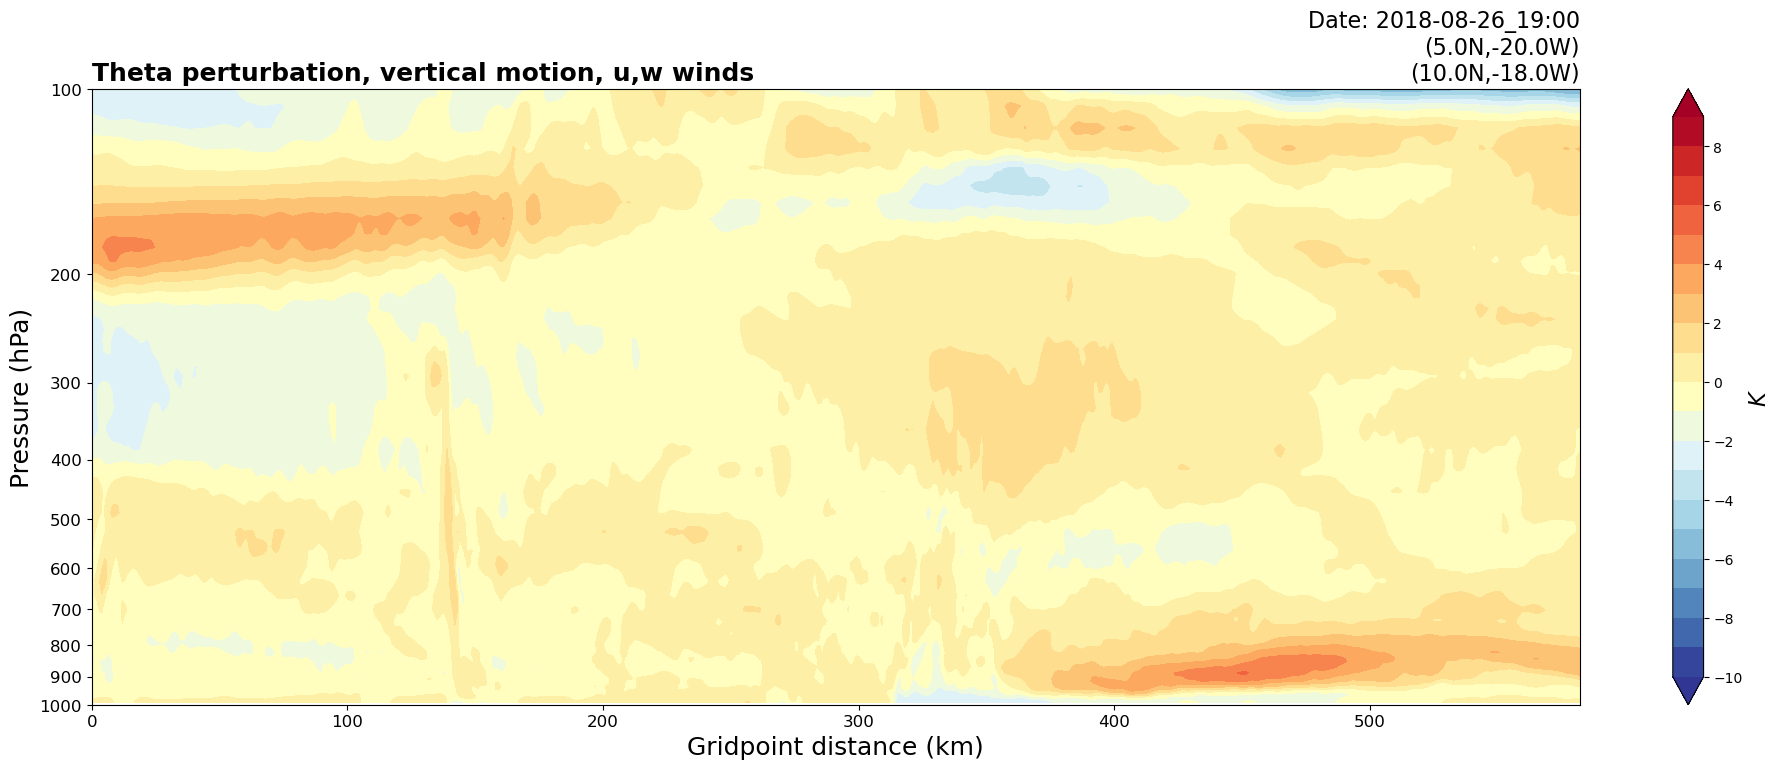

8
329
0.9414596
314
WRF valid time:  2018-08-26_19:30


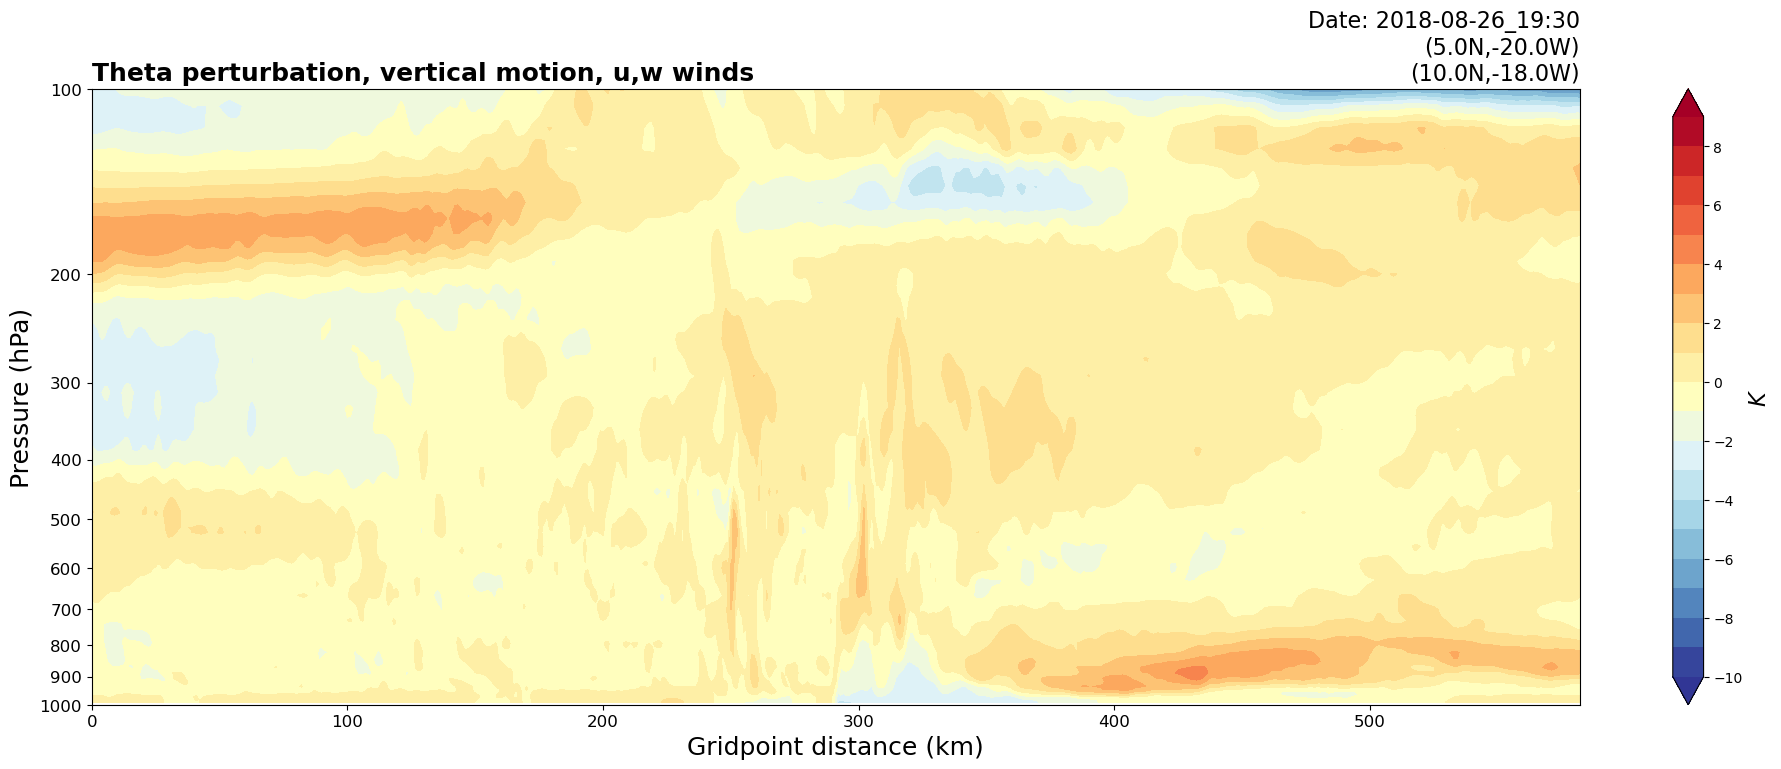

9
314
1.1342491
291
WRF valid time:  2018-08-26_20:00


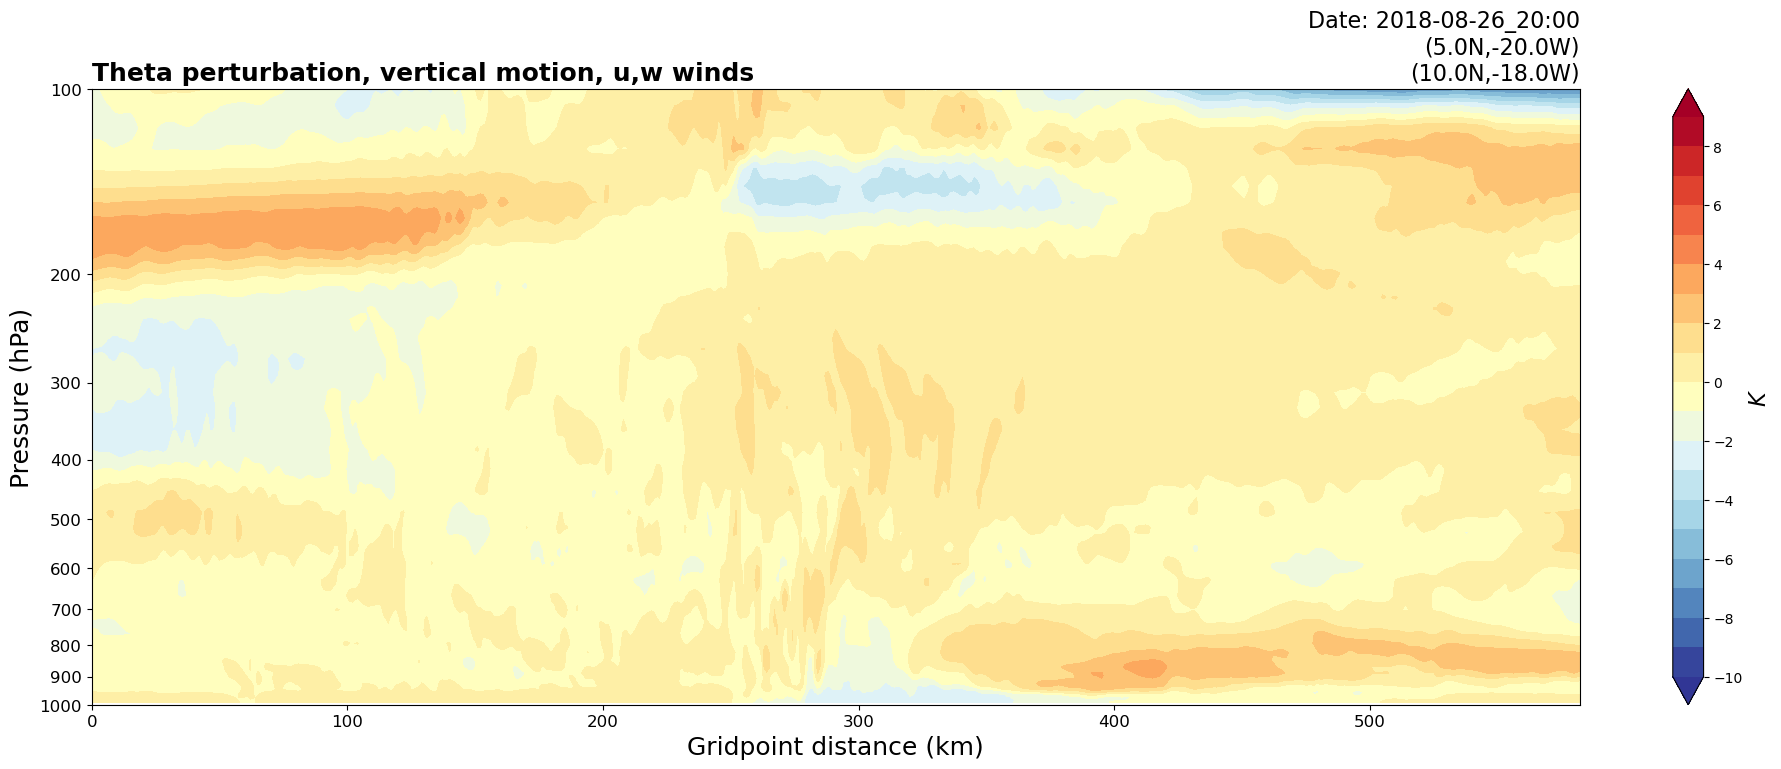

10
291
0.7809169
279
WRF valid time:  2018-08-26_20:30


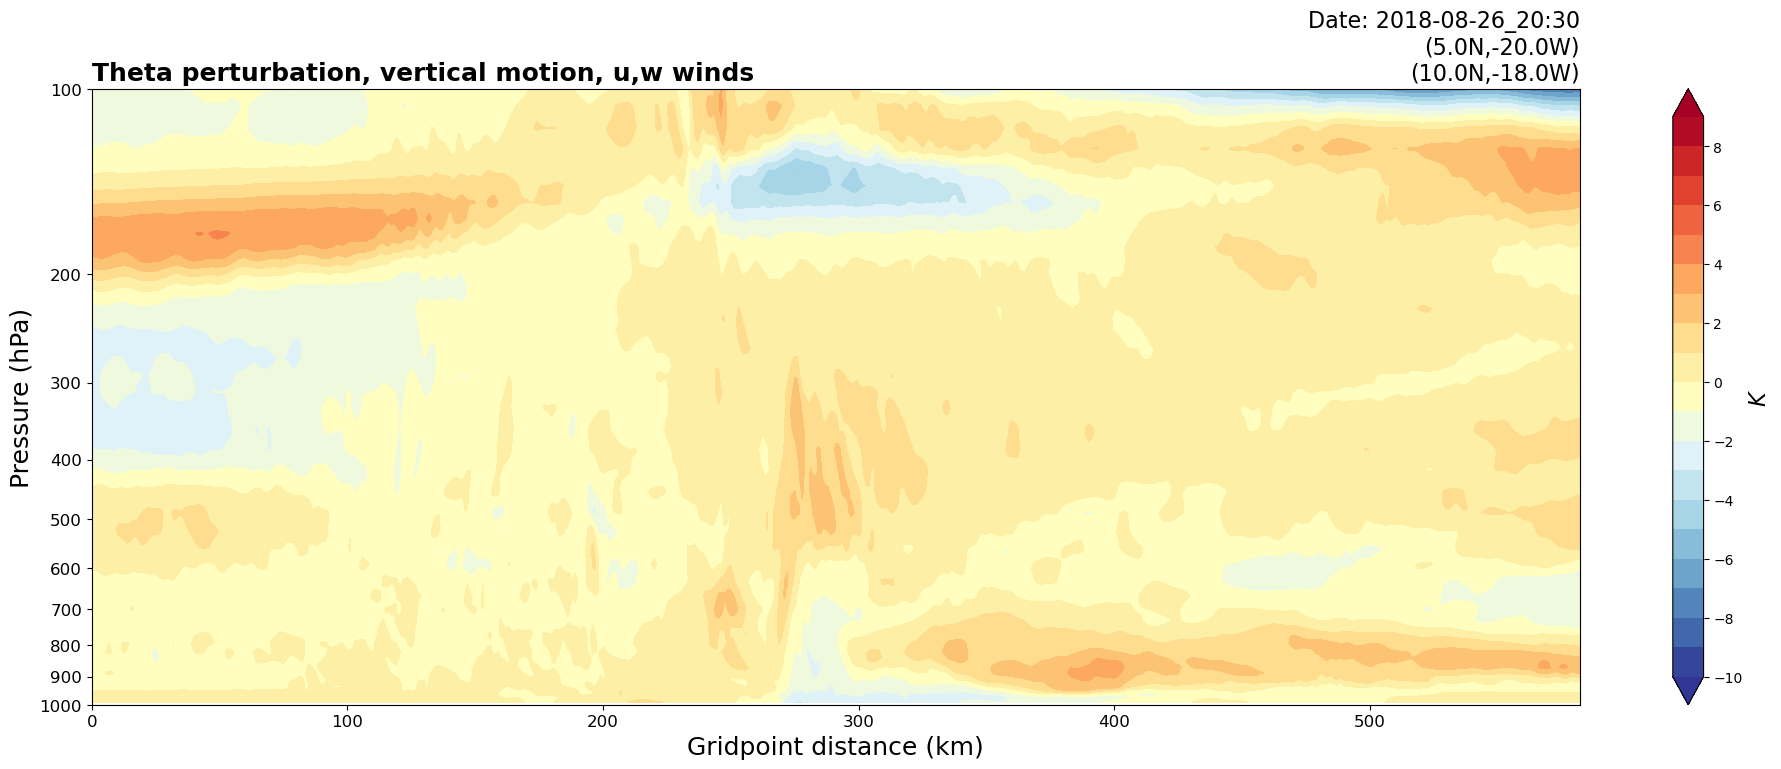

11
279
0.3454693
272
WRF valid time:  2018-08-26_21:00


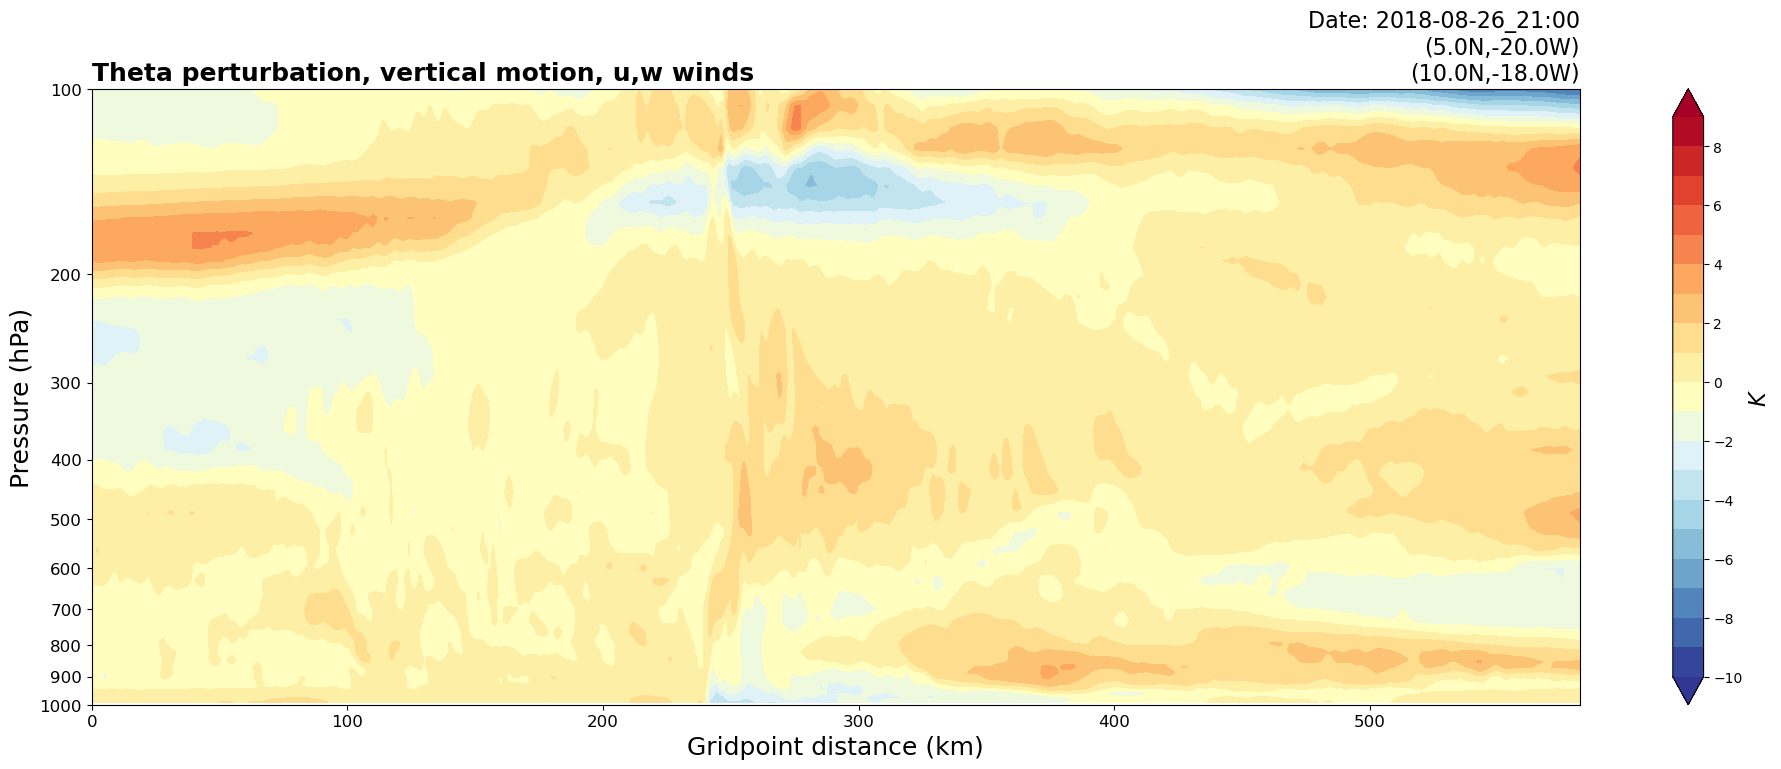

12
272
1.2825061
241
WRF valid time:  2018-08-26_21:30


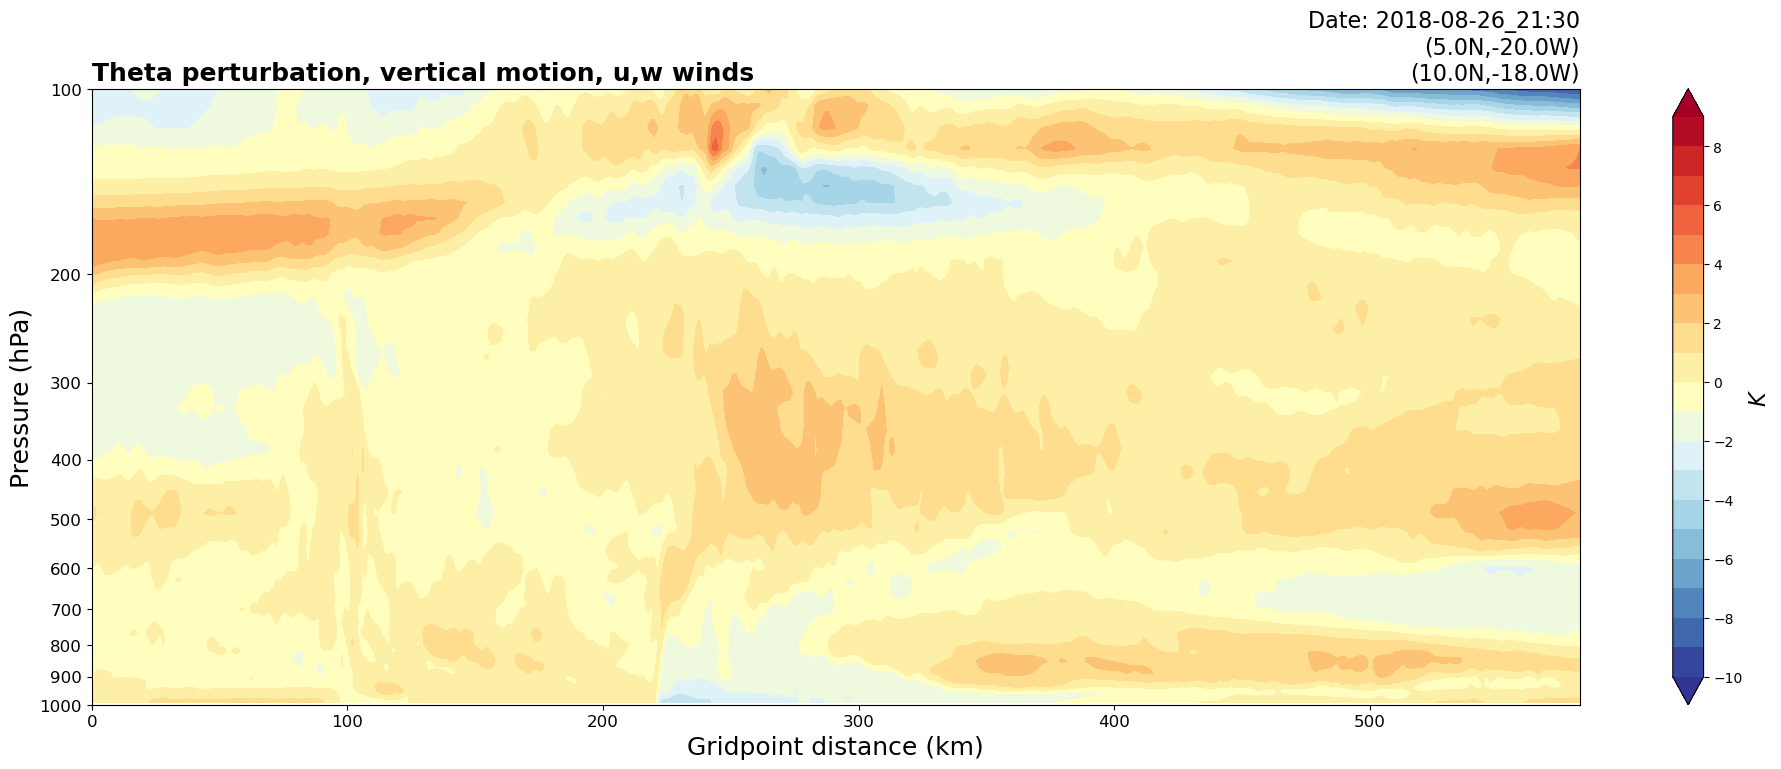

13
241
1.3267305
221
WRF valid time:  2018-08-26_22:00


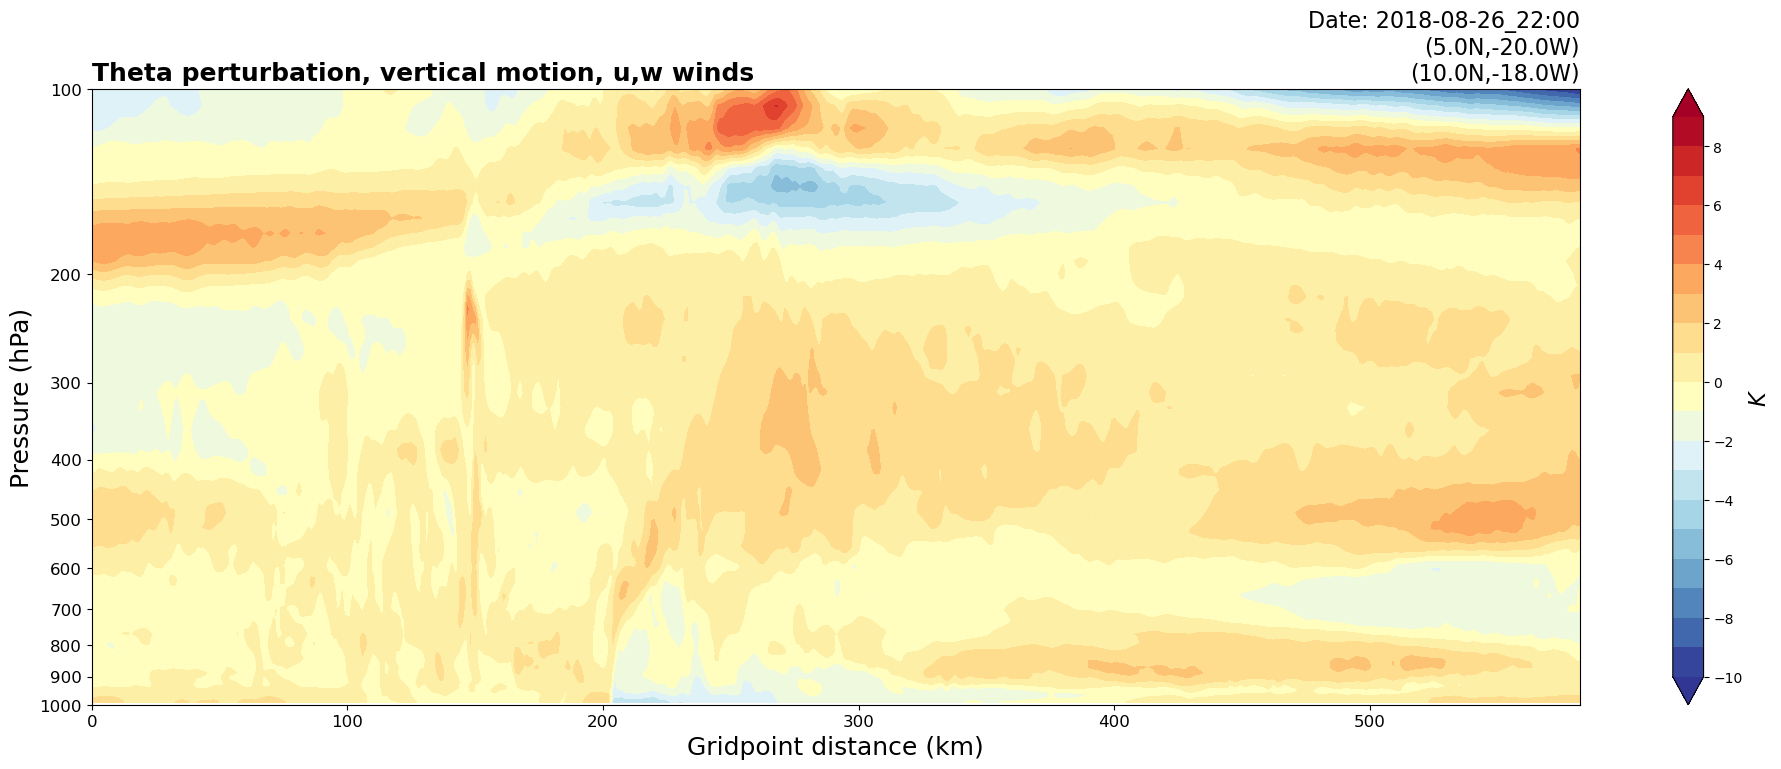

14
221
1.8744648
203
WRF valid time:  2018-08-26_22:30


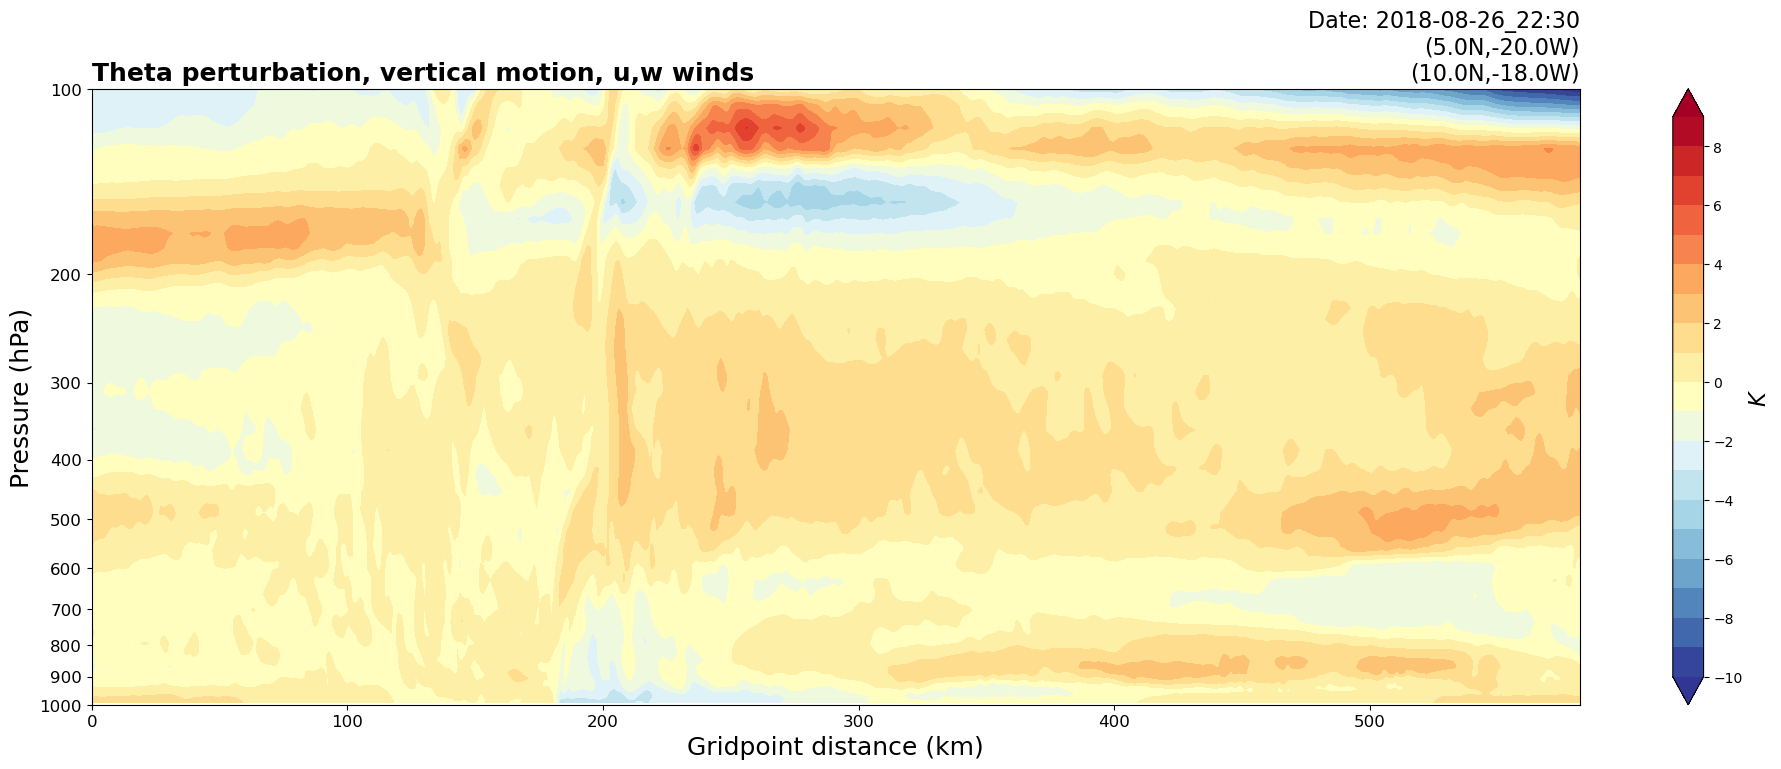

15
203
1.054783
182
WRF valid time:  2018-08-26_23:00


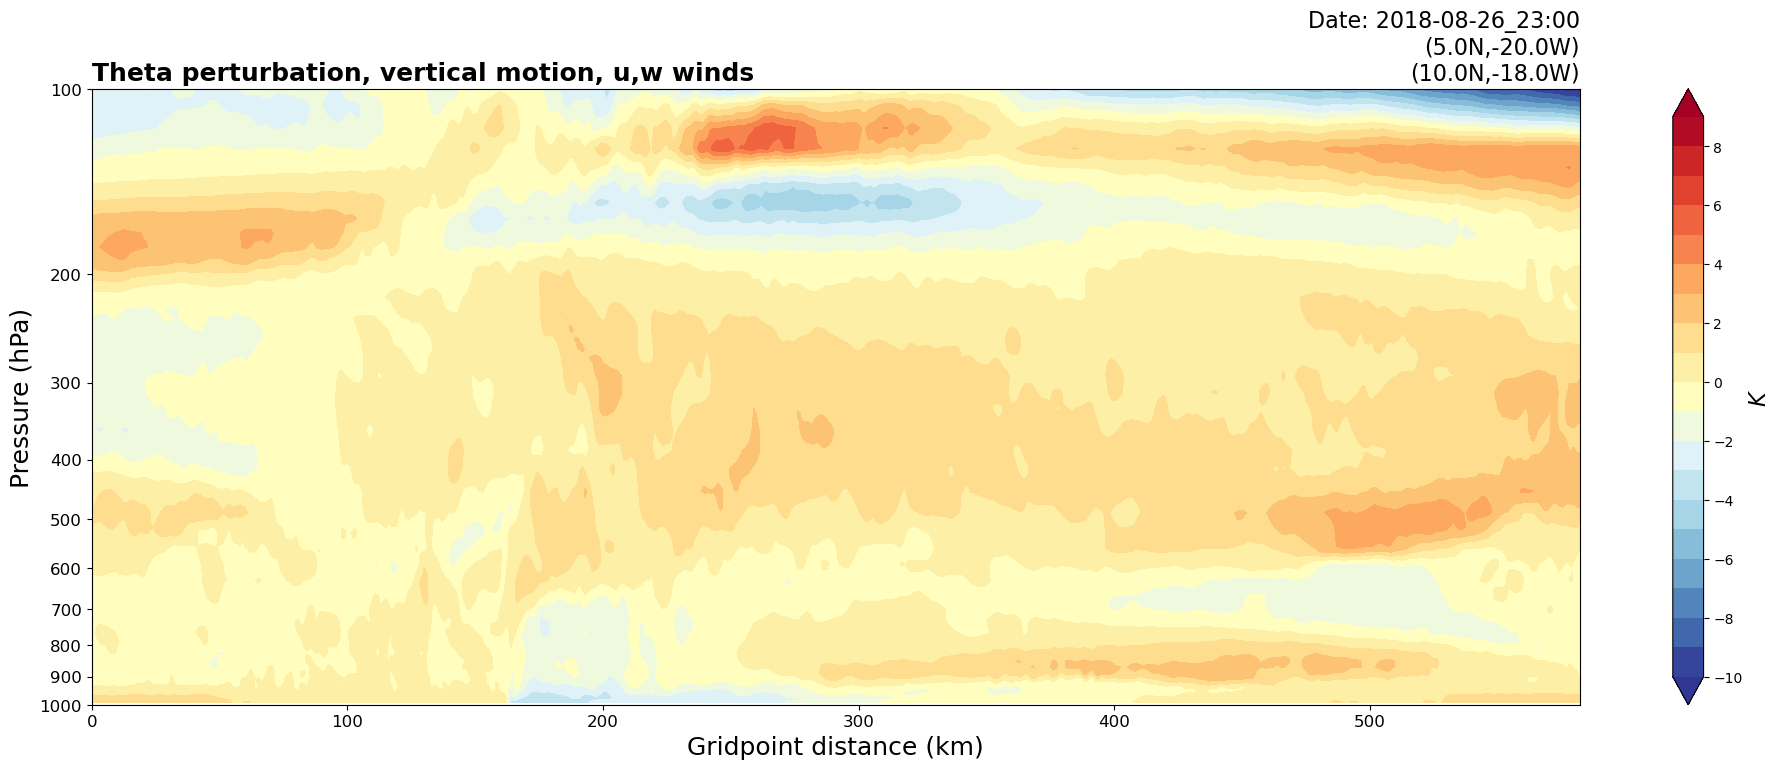

16
182
1.0712371
163
WRF valid time:  2018-08-26_23:30


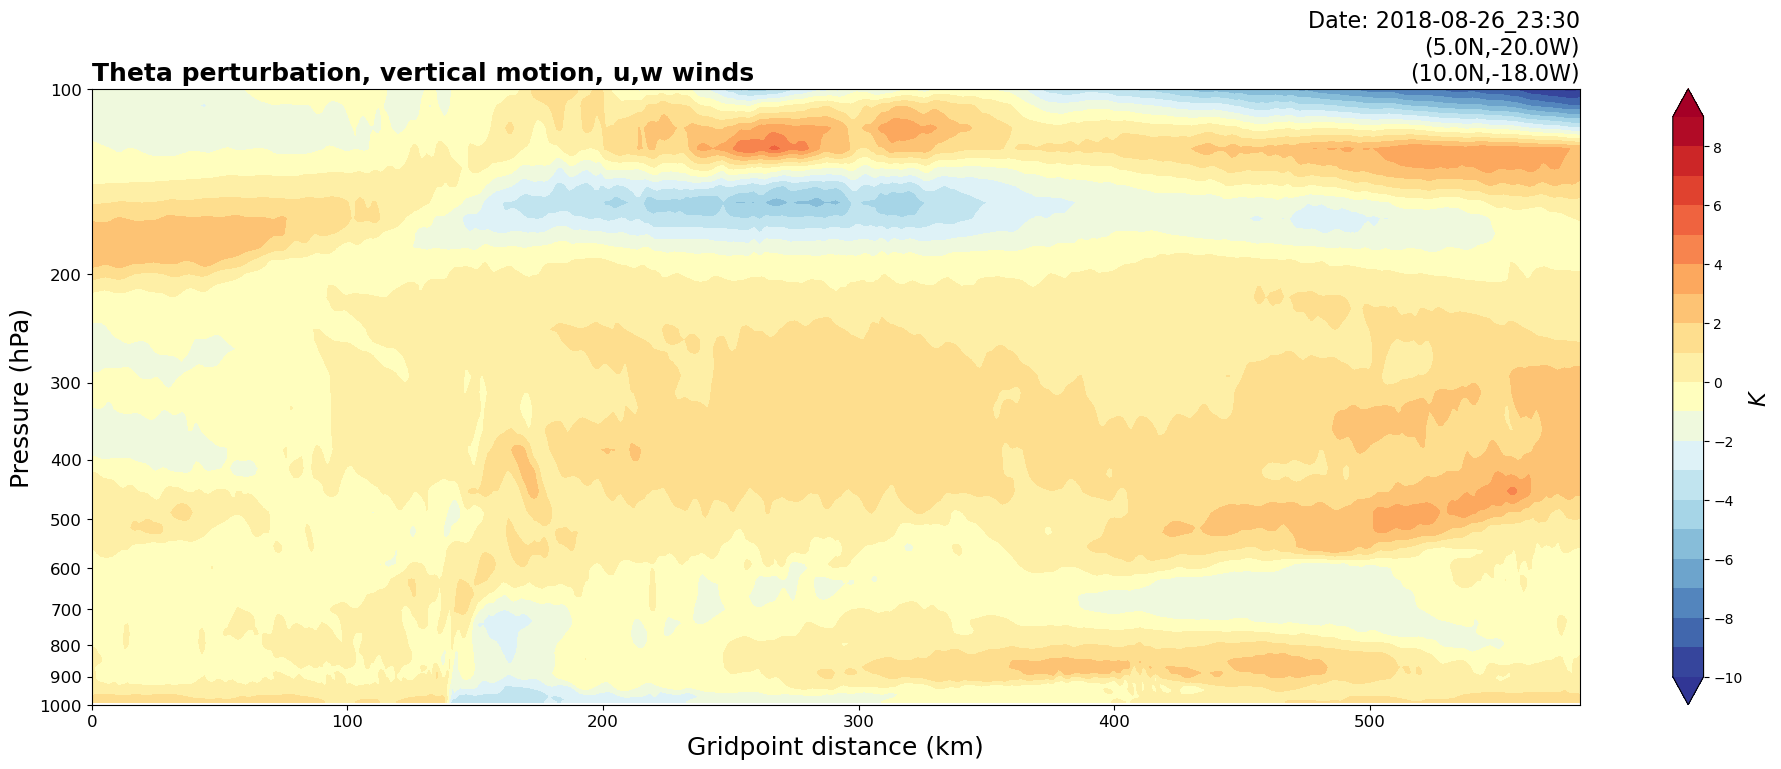

17
163
1.2371713
140
WRF valid time:  2018-08-27_00:00


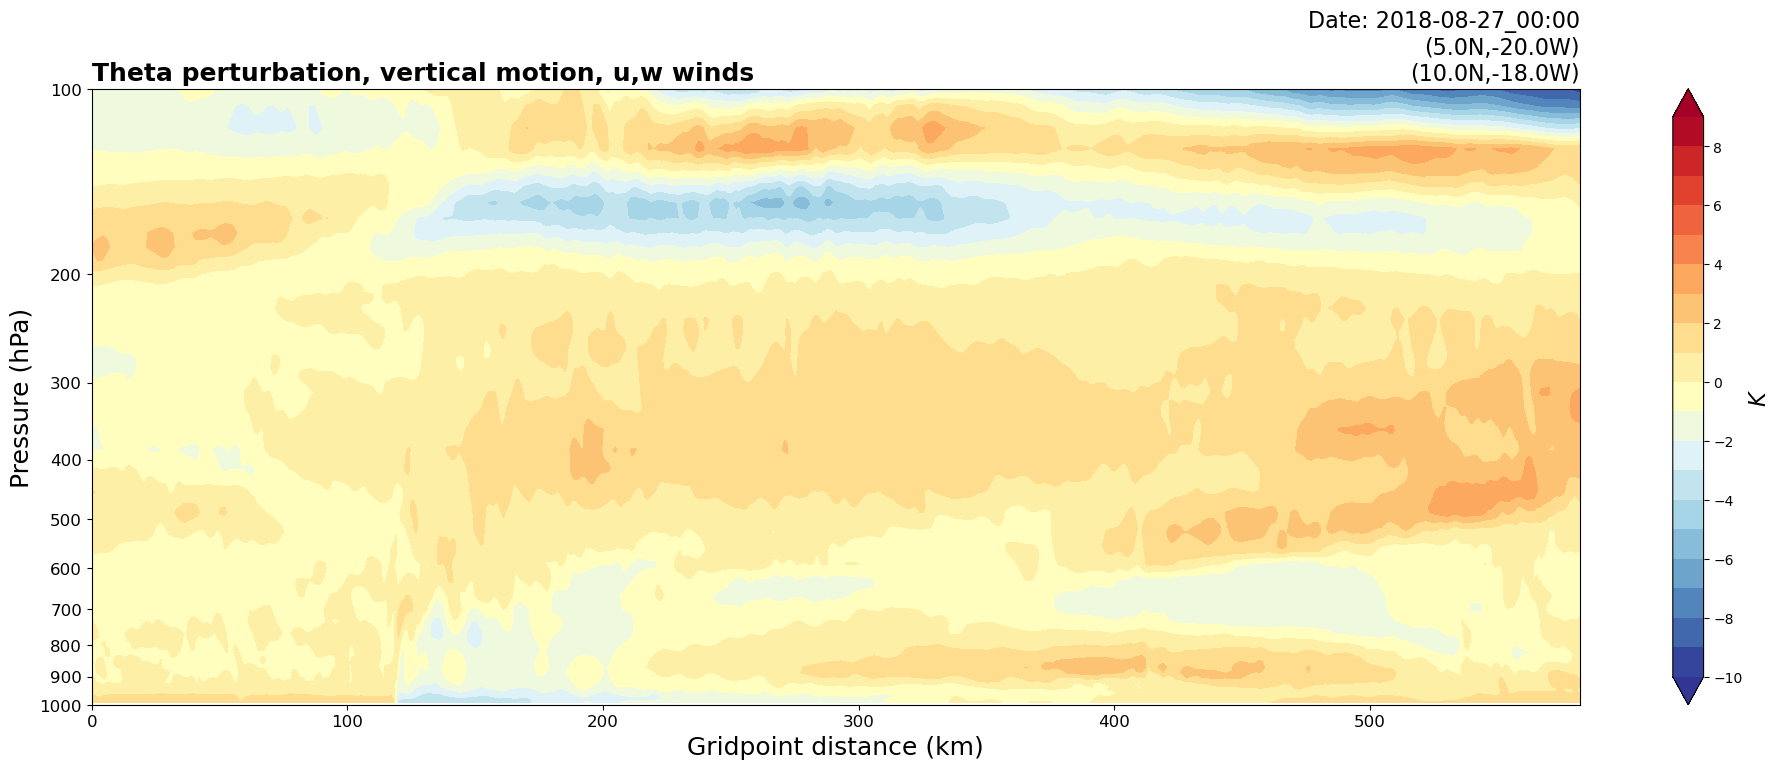

18
140
1.532701
119


In [9]:
max_list_idx = []
for i in range(65,85):  # for oceanic
    # Create an aerial abmient theta box ahead of the cross section
    ## for north and south MCSs
    try:
        ### For oceanic
        lat_max2 = 9 - (i-65)/7  
        lat_min2 = lat_max2 - 1
        lon_max2 = lon_max
        lon_min2 = lon_min
        
        idx = np.where(lat <= lat_min2)
        min_lat_idx_50 = idx[0][-1]
        idx = np.where(lat <= lat_max2)
        max_lat_idx_50 = idx[0][-1]
        
        idx = np.where(lon <= lon_min2)
        min_lon_idx_50 = idx[0][-1]
        idx = np.where(lon <= lon_max2)
        max_lon_idx_50 = idx[0][-1]
        
        wrf_out_data = xr.open_dataset(datafiles[i])
        ncfile = Dataset(datafiles[i])
        Time=wrf.extract_times(ncfile, timeidx=0, method='cat', squeeze=True, cache=None, meta=False, do_xtime=False)
        timestr=(str(Time))
        # Set up one time string for plot titles, another for file names
        titletime=(timestr[0:10]+' '+timestr[11:16])
        filetime=(timestr[0:10]+'_'+timestr[11:16])
        print('WRF valid time: ',filetime)
        
        ua = wrf_out_data["U"]
        va = wrf_out_data["V"]
        wa = wrf_out_data["W"]
        p = wrf_out_data["P"].metpy.quantify()
        pb = wrf_out_data["PB"].metpy.quantify()
        theta_p = wrf_out_data['T'].metpy.quantify()
        
        # Unstagger the winds to match the pressure grid
        ua = destagger(ua, stagger_dim=3)  # Unstagger U in the x-direction
        va = destagger(va, stagger_dim=2)  # Unstagger V in the x-direction
        wa = destagger(wa, stagger_dim=1)  # Unstagger W in the z-direction
        # Grid spacing for vorticity calculation
        dx = ncfile.DX * units("m")
        dy = ncfile.DY * units("m")
        
        u_winds = xr.DataArray(ua)[0]
        v_winds = xr.DataArray(va)[0]
        w_winds = xr.DataArray(wa)[0]
        pres = xr.DataArray(p)[0]
        pb = xr.DataArray(pb)[0]
        theta_p = xr.DataArray(theta_p)[0]
        
        pb = pb.metpy.convert_units('hPa')
        pres = pres.metpy.convert_units('hPa')
        pressure = pres + pb 
        
        # compute aerial average of full theta field 
        theta = theta_p + 300*units('K')            # add 300K to theta model perturbation
        theta_base = theta.sel(south_north=slice(min_lat_idx_50,max_lat_idx_50), 
                                    west_east=slice(min_lon_idx_50,max_lon_idx_50)).mean(dim={'south_north', 'west_east'})
        
        # compute the perturbation from this average, level by level
        theta_pert = theta - theta_base
        theta_pert_slice = theta_pert.sel(bottom_top=slice(0,10))
        pb_slice = pb.sel(bottom_top=slice(0,10))
        
        cross_section  = vertcross(theta_pert, pb, wrfin=ncfile,
                                start_point=start_point,
                                end_point=end_point,
                                latlon=True, meta=True)
        
        
        # Cross section is a 2D array (z vs distance)
        theta_p_cross = cross_section.values
        dist = np.arange(theta_p_cross.shape[1]) # becuase our innermost domain is 1 km, one grid point is approx 1 km
        height = cross_section.coords['vertical']
        f = create_fig()

        ## Getting the edge of the cold pool...
        ds = xr.DataArray(theta_p_cross)
        mean = ds[0:7,:].mean(dim='dim_0') # take the mean of the lowest 7 values of the theta perturbation
        grad = np.abs(np.gradient(mean))   # compute the gradient
        if i == 65:    ### For oceanic     # for the first point, append this to the empty list
            i_max = np.argmax(grad)
            max_list_idx.append(i_max)
        else:
            j = i-66   ### for oceanic     # for all other times, take the previous cold pool edge
            print(j)
            prev_index = max_list_idx[j]
            print(prev_index)
            grad_window = dist[prev_index-70:prev_index-6] # constrain the max theta to within 70 km of the previous point
            max = grad[grad_window].max() # find the max grad value
            print(max)
            i_max = np.argwhere(grad == max)[0][0] # find the index of this value
            print(i_max)
            max_list_idx.append(i_max) # append the index to this list
        # break the loop at the edge of teh domain 
    except ValueError:
        break

In [10]:
## compute ground relative speeds
dist_point = np.array(max_list_idx)
dist_list = []
for i in range(0,len(dist_point)-1):
    dist = dist_point[i+1] - dist_point[i]
    dist_list.append(dist)
dist = np.array(dist_list)
speed = (dist/1800)*1000

In [11]:
times_list = pd.date_range('2018-08-26 15:00', '2018-08-27 00:00',freq='0.5h') # oceanic MCS time frame

In [12]:
len(speed)

19

In [13]:
len(times_list)

19

In [14]:
# Create one dataset with u, v winds at each lat, lon, time coordinate for this ensemble member
ds = xr.Dataset( 
    coords=dict(
        time=("time", times_list),
        speed=("speed", speed),))

In [5]:
# apply regridding and save file
path_out = "/glade/u/home/athornton/wrf_visualization/cold_pool_data/"
file_out = path_out+'ocean_speed_thesis_shallow.nc'
ds.to_netcdf(path=file_out, format='NETCDF4', mode='w')

In [12]:
ocean_file = path_out+'ocean_speed_thesis_shallow.nc'
south_file = path_out+'south_speed_thesis_shallow.nc'
#north_file = path_out+'north_speed_thesis_shallow.nc'

In [13]:
ocean = xr.open_dataset(ocean_file)
south = xr.open_dataset(south_file)
#north = xr.open_dataset(north_file)

In [14]:
all_time = pd.date_range('2018-08-25 12:00', '2018-08-27 00:00',freq='0.5h')
lands = all_time[25] ## coastal passage for the south MCS
landn = all_time[43] ## coastal passage for the north MCS

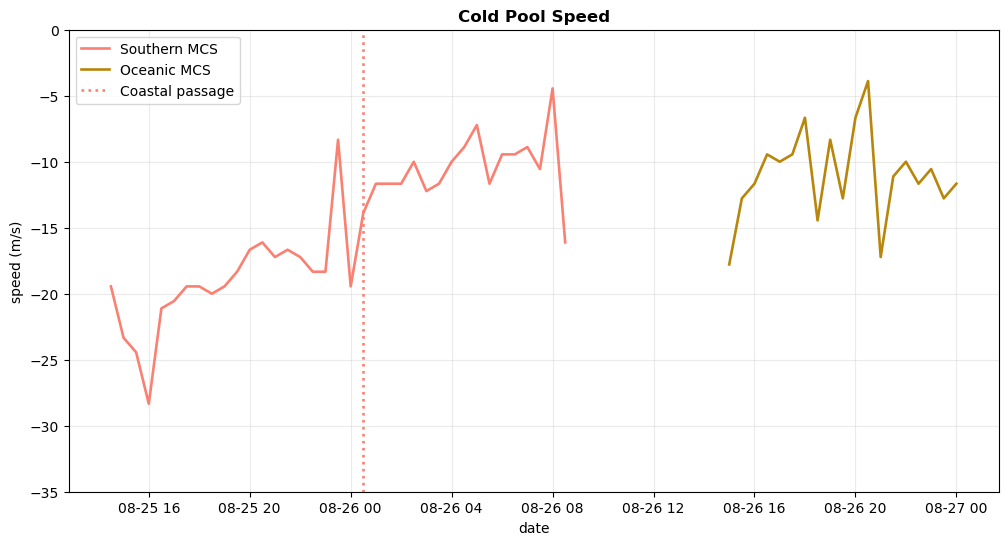

In [17]:
fig, ax = plt.subplots(1,figsize=(12,6))
ax.set_title('Cold Pool Speed', weight='bold')
ax.plot(south.time, south.speed, color='salmon', label='Southern MCS', linewidth=1.9)
#ax.plot(north.time, north.speed, color='steelblue',label='Northern MCS', linewidth=1.9)
ax.plot(ocean.time, ocean.speed, color='darkgoldenrod',label='Oceanic MCS', linewidth=1.9)
ax.axvline(x=lands, color='salmon', linestyle=':', label='Coastal passage', linewidth=1.9)
#ax.axvline(x=landn, color='steelblue', linestyle=':', label='Coastal passage', linewidth=1.9)
ax.grid(color='lightgray', alpha=0.45)
ax.set_ylim(-35, 0)
ax.set_ylabel('speed (m/s)')
ax.set_xlabel('date')
plt.legend()
#plt.savefig(plotsdir+'coldpoolspeed_no_north.png')